# 03 · Experimentos en MLflow

Este notebook **lee** lo que registró el pipeline (`pipelines/training_flow.py`) en MLflow:
comparación de algoritmos con cross-validation, búsqueda de hiperparámetros con Optuna (runs
anidados) y el modelo final registrado en el Model Registry.

> Requisito: haber corrido `uv run python pipelines/training_flow.py` al menos una vez.
> También se puede explorar lo mismo en la UI: `uv run mlflow ui --backend-store-uri sqlite:///mlflow.db`

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from informalidad.config import use_project_root
use_project_root()  # rutas relativas desde la raíz del proyecto

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#2a6fbb", "#e07b39", "#8a94a6"
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
import os
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"

import mlflow
from mlflow.tracking import MlflowClient
from informalidad.config import get_config

cfg = get_config()["mlflow"]
mlflow.set_tracking_uri(cfg["tracking_uri"])
runs = mlflow.search_runs(experiment_names=[cfg["experiment_name"]])
print(f"{len(runs)} runs en el experimento '{cfg['experiment_name']}'")

2026/10/12 18:13:03 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/claude/project/mlops-informalidad-laboral/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


26 runs en el experimento 'informalidad-laboral'


## 1. Comparación de algoritmos

In [3]:
comp = runs[runs["tags.stage"] == "comparacion"].copy()
comp = comp.drop_duplicates("tags.model_family")   # última corrida de cada algoritmo
cols = {"tags.model_family": "modelo", "metrics.cv_roc_auc_mean": "cv_auc",
        "metrics.cv_roc_auc_std": "cv_std", "metrics.valid_roc_auc": "valid_auc",
        "metrics.test_roc_auc": "test_auc", "metrics.test_f1": "test_f1"}
tabla = comp[list(cols)].rename(columns=cols).set_index("modelo").sort_values("test_auc")
tabla

,cv_auc,cv_std,valid_auc,test_auc,test_f1
modelo,,,,,
baseline_dummy,0.5000,0.0000,0.5000,0.5000,0.7143
logistic_regression,0.9527,0.0020,0.9528,0.9517,0.8902
random_forest,0.9666,0.0023,0.9665,0.9623,0.8991
xgboost,0.9732,0.0017,0.9737,0.9709,0.9163


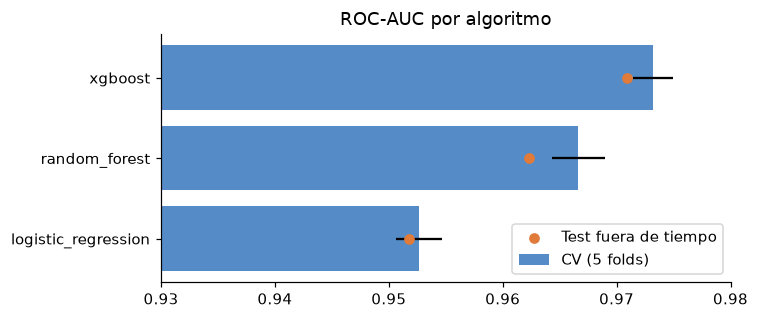

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
t = tabla.drop(index="baseline_dummy", errors="ignore")
ax.barh(t.index, t["cv_auc"], xerr=t["cv_std"], color=AZUL, alpha=0.8, label="CV (5 folds)")
ax.scatter(t["test_auc"], t.index, color=NARANJA, zorder=3, label="Test fuera de tiempo")
ax.set_xlim(0.93, 0.98); ax.legend(loc="lower right"); ax.set_title("ROC-AUC por algoritmo")
fig.tight_layout()

XGBoost gana en CV, validación y test. La diferencia entre CV y test es pequeña: el modelo
**generaliza a meses que no vio**.

## 2. Optimización con Optuna (runs anidados)

,mejor valor
learning_rate,0.12179459222739866
max_depth,6
min_child_weight,6.3466422826574425
colsample_bytree,0.8125407241075986
n_estimators,400
subsample,0.9089739131201203
reg_lambda,2.9491081133559796


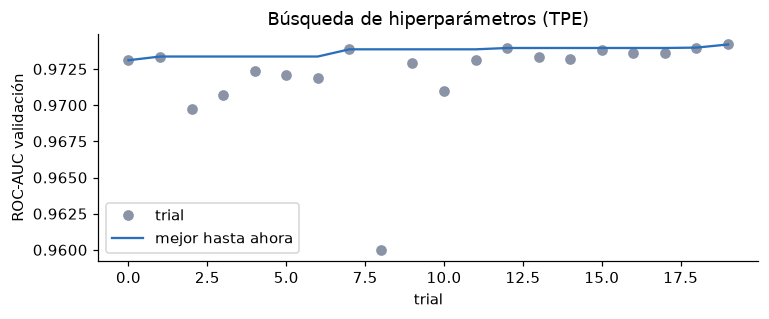

In [5]:
parent = runs[runs["tags.mlflow.runName"] == "xgboost_optuna"].iloc[0]
trials = runs[runs["tags.mlflow.parentRunId"] == parent["run_id"]].copy()
trials["trial"] = trials["tags.mlflow.runName"].str.replace("trial_", "").astype(int)
trials = trials.sort_values("trial")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(trials["trial"], trials["metrics.valid_roc_auc"], "o", color=GRIS, label="trial")
ax.plot(trials["trial"], trials["metrics.valid_roc_auc"].cummax(), color=AZUL, label="mejor hasta ahora")
ax.set_xlabel("trial"); ax.set_ylabel("ROC-AUC validación"); ax.legend()
ax.set_title("Búsqueda de hiperparámetros (TPE)")
fig.tight_layout()

best_params = {k.replace("params.best_", ""): v for k, v in parent.items()
               if k.startswith("params.best_") and pd.notna(v)}
pd.Series(best_params, name="mejor valor").to_frame()

## 3. Modelo final y Model Registry

In [6]:
final = runs[runs["tags.stage"] == "final"].iloc[0]
metricas = {k.replace("metrics.", ""): v for k, v in final.items()
            if k.startswith("metrics.test_") and pd.notna(v)}
print("Umbral de decisión (máximo F1 en validación):", final["params.threshold"])
pd.Series(metricas, name="test fuera de tiempo").to_frame()

Umbral de decisión (máximo F1 en validación): 0.494901


,test fuera de tiempo
test_f1,0.9185
test_recall,0.9036
test_pr_auc,0.9773
test_precision,0.9338
test_roc_auc,0.9717
test_brier,0.0650
test_accuracy,0.9109


In [7]:
client = MlflowClient()
nombre = cfg["registered_model_name"]
alias_por_version = {}
for alias, version in client.get_registered_model(nombre).aliases.items():
    alias_por_version.setdefault(str(version), []).append(alias)
versiones = client.search_model_versions(f"name='{nombre}'")
pd.DataFrame([{
    "version": v.version,
    "aliases": ", ".join(alias_por_version.get(str(v.version), [])) or "-",
    "test_roc_auc": v.tags.get("test_roc_auc"),
    "promovido": v.tags.get("promoted_to_champion"),
    "run_id": v.run_id[:8],
} for v in versiones]).sort_values("version")

,version,aliases,test_roc_auc,promovido,run_id
0,1,"candidate, champion",0.9717,True,117fac3f


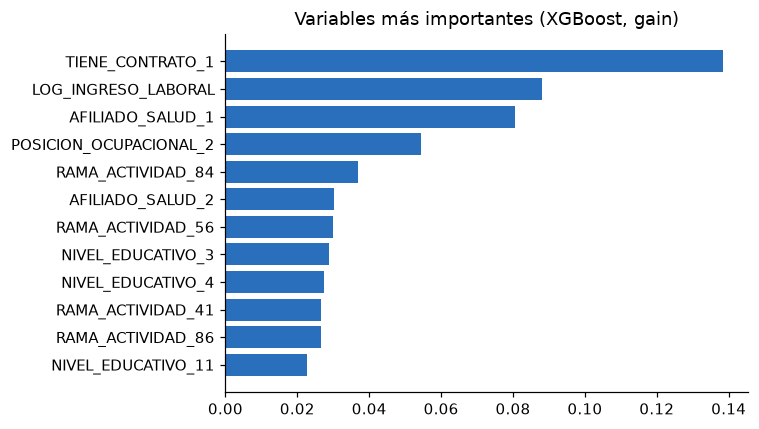

In [8]:
import tempfile
with tempfile.TemporaryDirectory() as tmp:
    ruta = mlflow.artifacts.download_artifacts(
        run_id=final["run_id"], artifact_path="evaluation/feature_importance.csv", dst_path=tmp)
    importancia = pd.read_csv(ruta)

top = importancia.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top["feature"], top["importance"], color=AZUL)
ax.set_title("Variables más importantes (XGBoost, gain)")
fig.tight_layout()

## Conclusiones

- **Champion:** XGBoost optimizado con Optuna, con preprocesamiento dentro del Pipeline.
- Supera las métricas de éxito definidas en `02_baseline` (AUC ≥ 0.95 y > regresión logística).
- La ganancia de Optuna sobre XGBoost por defecto es pequeña: el problema está dominado por pocas
  variables muy informativas (contrato, ingreso, afiliación a salud, posición ocupacional y nivel
  educativo). Más trials no cambiarían mucho;
  mejoras futuras vendrían de **nuevas variables**, no de más búsqueda de hiperparámetros.
- La regla de promoción compara candidato vs champion **sobre los mismos datos**, así un
  reentrenamiento automático nunca empeora el modelo en producción.